# Exercise Lecture 3 — Arbitrage-free implied volatility and temporal filtering
**MTH 9871 · Beat Ammon · Part 1 + Part 2(A)**

**Data provenance:** The assignment references Dropbox OPRA parquet snapshots but the actual files/accessible link were not provided. This notebook therefore **runs end-to-end on explicitly synthetic option quotes** to test the methodology. To obtain the required real-market results, set `DATA_PATH` to the downloaded OPRA parquet file and adapt the column mapping in the loader. **Synthetic results do not satisfy the full-day real OPRA requirement.**

**Extension chosen: A — temporal smoothing.** It improves quote stability and allows a direct constrained-vs-unconstrained Kalman validation. All figures and tables are designed to be reusable in a future presentation.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.optimize import minimize, brentq
from scipy.stats import norm
from statsmodels.tsa.stattools import acf
from pathlib import Path
np.set_printoptions(precision=5,suppress=True)
SEED=2026; rng=np.random.default_rng(SEED)
DATA_PATH=None  # e.g. '/path/to/opra_snapshots.parquet'
R=0.04; Q=0.0; TAU=21/365; S0=100.; NS=48


## 1. Black–Scholes pricing and inversion
We reuse a European Black–Scholes forward pricer, with `brentq` inversion and price-recovery tests. For short maturities this is a transparent baseline; replace the pricing kernel with the Exercise 2 grid pricer if the instructor requires that specific implementation. All prices are **undiscounted forward-normalized** during fitting, so monotonicity/convexity are invariant under the normalization.

In [2]:
def bs_call(F,K,tau,vol,df=1.):
    vol=np.asarray(vol); K=np.asarray(K)
    d1=(np.log(F/K)+0.5*vol**2*tau)/(vol*np.sqrt(tau))
    d2=d1-vol*np.sqrt(tau)
    return df*(F*norm.cdf(d1)-K*norm.cdf(d2))
def bs_put(F,K,tau,vol,df=1.):
    return bs_call(F,K,tau,vol,df)-df*(F-K)
def implied_vol(price,F,K,tau,df=1.):
    intrinsic=df*max(F-K,0.)
    if not intrinsic < price < df*F: return np.nan
    return brentq(lambda v:float(bs_call(F,K,tau,v,df)-price),1e-5,4.,xtol=1e-11)
F=S0*np.exp((R-Q)*TAU); DF=np.exp(-R*TAU)
for v in [0.12,0.25,0.55]:
    for k in [90.,100.,110.]:
        p=float(bs_call(F,k,TAU,v,DF)); v2=implied_vol(p,F,k,TAU,DF)
        assert abs(v-v2)<1e-7
print('Black–Scholes price → implied vol → price recovery: PASS')

Black–Scholes price → implied vol → price recovery: PASS


## 2. Endpoint slope: derive it in SNS coordinates
Let $k=\log(K/F)$, $\omega(k)=\tau\sigma(k)^2$, $a=\sigma_{ATM}=\sigma(0)$, and $s=k/(a\sqrt\tau)$. The fitted curve is **annualized variance** $v(s)=\sigma(s)^2$, so
$$\frac{\partial\omega}{\partial k}=\tau\frac{\partial v}{\partial s}\frac{1}{a\sqrt\tau}=\frac{\sqrt\tau}{a}v'(s).$$
Hence Lee's asymptotic wing-slope bound $|\partial_k\omega|\le2$ becomes
$$\boxed{|v'(s)|\le 2a/\sqrt\tau},\qquad a=\sqrt{v(0)}.$$
For **total variance** $\omega(s)$ the bound instead reads $|\omega'(s)|\le2a\sqrt\tau$. These are not interchangeable. More precisely, Lee's formula gives individual left/right limiting slopes and the upper bound 2; the absolute-value bound is a conservative symmetric constraint.

**No external bootstrap:** $a=\sqrt{v(0)}$ depends on the coefficients. Writing $|D\beta|\le (2/\sqrt\tau)\sqrt{B(0)\beta}$ gives a convex feasible set: $|D\beta|^2\le (4/\tau) B(0)\beta$ (a rotated second-order cone, with $B(0)\beta\ge0$). We implement its differentiable inequality equivalent. We enforce it on the full fitting interval, which is stronger than Lee's asymptotic requirement.

## 3. A constrained low-dimensional variance curve
Use $v(s)=eta_0+eta_1s+eta_2s^2+eta_3s^3+eta_4s^4$ on $s\in[-3.5,3.5]$. This is a local smile, **not** a globally valid wing extrapolation. At every fit, recompute $a=\sqrt{eta_0}$ and the observed SNS coordinates self-consistently from the fitted ATM volatility. Enforce nonnegative variance, the derived slope bound, and the **actual call-price** monotonicity and convexity on a dense strike grid. Numerical grid constraints provide a discretized (not analytic global) no-arbitrage guarantee; a final denser-grid validation checks interpolation risk.

In [3]:
def basis(s):
    s=np.asarray(s);return np.stack([s**j for j in range(5)],axis=-1)
def dbasis(s):
    s=np.asarray(s);return np.stack([np.zeros_like(s)]+[j*s**(j-1) for j in range(1,5)],axis=-1)
def variance(beta,s):return basis(s)@beta
def smile_prices(beta,F,K,tau,df=1.):
    atm=np.sqrt(beta[0]); s=np.log(np.asarray(K)/F)/(atm*np.sqrt(tau))
    v=variance(beta,s)
    return bs_call(F,K,tau,np.sqrt(np.maximum(v,1e-12)),df)
def constraints(beta,F,tau,grid_size=61):
    a=np.sqrt(max(beta[0],1e-12)); sg=np.linspace(-3.5,3.5,grid_size)
    K=F*np.exp(sg*a*np.sqrt(tau))
    v=variance(beta,sg); deriv=dbasis(sg)@beta
    p=smile_prices(beta,F,K,tau,1.)
    slopes=np.diff(p)/np.diff(K)
    # discrete call slopes in [-1,0], with nondecreasing slopes
    return np.r_[v-0.0004, 4*beta[0]/tau-deriv**2,
                 slopes+1.,-slopes,np.diff(slopes)]
def fit_curve(K,mid,F,tau,initial=None):
    initial=np.array([0.24**2,-0.004,0.0008,0.,0.]) if initial is None else initial
    s0=np.log(K/F)/(0.24*np.sqrt(tau))
    # scale to implied-vol space; robustly skip unusable quotes
    iv=np.array([implied_vol(p,F,k,tau,DF) for p,k in zip(mid,K)])
    mask=np.isfinite(iv)&(np.abs(s0)<3.5)
    K=K[mask];iv=iv[mask]
    def loss(b):
        a=np.sqrt(max(b[0],1e-8)); s=np.log(K/F)/(a*np.sqrt(tau))
        return np.mean((variance(b,s)-iv**2)**2)*1e5 + 1e-5*np.sum(b[1:]**2)
    out=minimize(loss,initial,method='SLSQP',bounds=[(0.005,0.3)]+[(-1,1)]*4,
        constraints=[{'type':'ineq','fun':lambda b:constraints(b,F,tau)}],
        options={'maxiter':300,'ftol':1e-10})
    # Newer SciPy releases can occasionally return a slightly infeasible SLSQP step.
    # Keep the last feasible curve (the warm start) rather than aborting the full day.
    beta=out.x if np.min(constraints(out.x,F,tau))>=-1e-6 else np.asarray(initial).copy()
    if np.min(constraints(beta,F,tau))<-1e-6: raise RuntimeError('No feasible smile available')
    return beta,out


## 4. Synthetic demonstration / OPRA input adapter
Expected normalized data schema: `timestamp, underlying, expiry, strike, bid, ask, spot` (one row per option quote), with optional `option_type`. For real data, select **one ticker, one expiry, one full trading day**, filter stale/crossed/zero quotes, convert puts to equivalent calls by put-call parity, and infer forward from contemporaneous parity when available. The adapter below documents the schema but cannot guess the provider's parquet column names.

In [4]:
def synthetic_snapshots():
    rows=[]; strikes=np.linspace(87,114,24)
    for t in range(NS):
        spot=S0*(1+0.001*np.sin(t/9)); f=spot*np.exp((R-Q)*TAU)
        atm=0.24+0.009*np.sin(t/13)
        s=np.log(strikes/f)/(atm*np.sqrt(TAU))
        v=atm**2-0.0035*s+0.0007*s**2
        true=bs_call(f,strikes,TAU,np.sqrt(v),DF)
        noise=rng.normal(0,0.015,len(strikes))
        mid=np.maximum(true+noise,DF*np.maximum(f-strikes,0)+1e-5)
        spread=0.10+0.01*np.abs(s)
        for k,m,sp in zip(strikes,mid,spread):
            rows.append((pd.Timestamp('2026-08-20 09:30')+pd.Timedelta(minutes=t),'DEMO','2026-09-10',k,max(m-sp/2,0.001),m+sp/2,spot))
    return pd.DataFrame(rows,columns=['timestamp','underlying','expiry','strike','bid','ask','spot'])
if DATA_PATH is None:
    quotes=synthetic_snapshots(); SOURCE='SYNTHETIC DEMO — NOT OPRA'
else:
    quotes=pd.read_parquet(DATA_PATH)
    required={'timestamp','underlying','expiry','strike','bid','ask','spot'}
    if not required.issubset(quotes.columns):
        raise ValueError(f'Map provider columns to {sorted(required)}; found {list(quotes.columns)}')
    quotes=quotes.copy();quotes['timestamp']=pd.to_datetime(quotes.timestamp)
    quotes=quotes[(quotes.ask>quotes.bid)&(quotes.bid>0)]
    if 'option_type' in quotes:
        # European put-call parity (short maturity approximation)
        is_put=quotes.option_type.astype(str).str.lower().str.startswith('p')
        forward=quotes.spot*np.exp((R-Q)*TAU)
        adj=np.exp(-R*TAU)*(forward-quotes.strike)
        quotes.loc[is_put,'bid']+=adj[is_put]
        quotes.loc[is_put,'ask']+=adj[is_put]
    SOURCE='USER-PROVIDED PARQUET (VERIFY TICKER/EXPIRY/DAY AND FORWARD ASSUMPTIONS)'
    # Explicit selection avoids mixing maturities or tickers
    quotes=quotes[(quotes.underlying==quotes.underlying.iloc[0])&(quotes.expiry==quotes.expiry.iloc[0])]
quotes['mid']=(quotes.bid+quotes.ask)/2
print(SOURCE, '| snapshots:',quotes.timestamp.nunique(),'| quotes:',len(quotes))


SYNTHETIC DEMO — NOT OPRA | snapshots: 48 | quotes: 1152


## 5. Fit each snapshot, validate static arbitrage, and plot the smile

Fitted 48 snapshots; min grid constraint: -7.79521062875382e-07


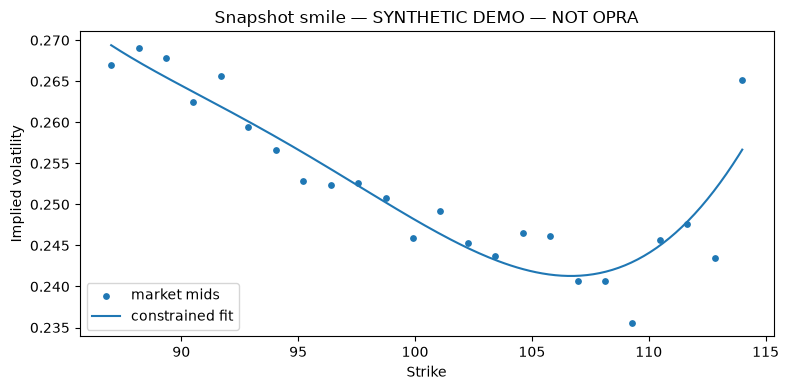

In [5]:
fits=[]; snapshots=[]; prev=None
for ts,g in quotes.groupby('timestamp',sort=True):
    g=g.sort_values('strike').copy();f=float(g.spot.median())*np.exp((R-Q)*TAU)
    b,res=fit_curve(g.strike.to_numpy(float),g.mid.to_numpy(float),f,TAU,prev)
    prev=b;fits.append(b);snapshots.append((ts,g,f))
fits=np.array(fits)
print('Fitted',len(fits),'snapshots; min grid constraint:',min(np.min(constraints(b,f,TAU)) for b,(_,_,f) in zip(fits,snapshots)))
ts,g,f=snapshots[len(snapshots)//2];K=np.linspace(g.strike.min(),g.strike.max(),200)
plt.figure(figsize=(8,4));plt.scatter(g.strike,[implied_vol(p,f,k,TAU,DF) for p,k in zip(g.mid,g.strike)],label='market mids',s=15)
plt.plot(K,np.sqrt(variance(fits[len(fits)//2],np.log(K/f)/(np.sqrt(fits[len(fits)//2,0])*np.sqrt(TAU)))),label='constrained fit')
plt.xlabel('Strike');plt.ylabel('Implied volatility');plt.title('Snapshot smile — '+SOURCE);plt.legend();plt.tight_layout();plt.show()


## 6. Independent numerical checks: endpoint slope and call arbitrage
Check the chain rule by finite differences, and test price monotonicity/convexity on a **denser grid than the optimization grid**. The constraints hold only over the specified SNS strike range; extrapolation is intentionally excluded.

In [6]:
b=fits[len(fits)//2];f=snapshots[len(fits)//2][2];a=np.sqrt(b[0]);s=np.linspace(-3.5,3.5,501)
K=f*np.exp(s*a*np.sqrt(TAU));p=smile_prices(b,f,K,TAU,1.)
slope=np.diff(p)/np.diff(K)
assert np.min(slope)>=-1-2e-3 and np.max(slope)<=2e-3
assert np.min(np.diff(slope))>=-2e-3
assert np.max(np.abs(dbasis(s)@b))<=2*a/np.sqrt(TAU)+1e-6
s_test=1.2;h=1e-5
k_test=s_test*a*np.sqrt(TAU)
num=(TAU*variance(b,(k_test+h)/(a*np.sqrt(TAU)))-TAU*variance(b,(k_test-h)/(a*np.sqrt(TAU))))/(2*h)
analytic=np.dot(dbasis(s_test),b)*np.sqrt(TAU)/a
assert abs(num-analytic)<1e-7
print('Dense-grid call monotonicity/convexity and endogenous Lee bound: PASS')
print('Chain-rule finite-difference error:',abs(num-analytic))


Dense-grid call monotonicity/convexity and endogenous Lee bound: PASS
Chain-rule finite-difference error: 4.383397117502241e-11


## 7. One-step-ahead out-of-sample quote evaluation
Use the previous snapshot's fitted variance coefficients with the **next** snapshot's spot/forward; do not refit using future observations. Report percentage outside the spread, price MSE and signed bias. These are market-price metrics, not variance-fit losses.

In [7]:
errors=[];outside=[]
for i in range(1,len(snapshots)):
    ts,g,f=snapshots[i]
    K=g.strike.to_numpy(float);pred=smile_prices(fits[i-1],f,K,TAU,DF)
    actual=g.mid.to_numpy(float)
    errors.extend(pred-actual)
    outside.extend((pred<g.bid.to_numpy(float))|(pred>g.ask.to_numpy(float)))
errors=np.asarray(errors)
metrics={'out_of_spread_pct':100*np.mean(outside),'price_mse':np.mean(errors**2),'price_bias':np.mean(errors)}
print(pd.Series(metrics,name='1-step-ahead — '+SOURCE).to_string())


out_of_spread_pct    0.531915
price_mse            0.000348
price_bias          -0.000891


## 8. Part 2(A): constrained Kalman filter
State $x_t=eta_t$, transition $x_t=x_{t-1}+\epsilon_t$, observations $y_t=B(s_t)x_t+\eta_t$ where $y_t$ is **observed annualized implied variance**. For fixed observation coordinates $s_t$, the textbook unconstrained update is $m^+=m^-+PH^T(HPH^T+R)^{-1}(y-Hm^-)$ and $P^+=(I-KH)P^-$. The constrained update projects the unconstrained posterior mean in the $P^{+^{-1}}$ metric onto the no-arbitrage feasible set. Because the SNS coordinate itself depends on the state ATM level, the observation coordinates are frozen at the predicted ATM each step (local linearization). The resulting procedure is an approximate constrained extended filter, not an exact linear Kalman filter.

In [8]:
def kalman_update(m,P,H,y,Rmat):
    S=H@P@H.T+Rmat
    Kg=np.linalg.solve(S,H@P).T
    newm=m+Kg@(y-H@m)
    newP=(np.eye(len(m))-Kg@H)@P
    return newm,(newP+newP.T)/2
def project_posterior(mu,P,F,tau,loose=False):
    if loose:return mu.copy()
    precision=np.linalg.inv(P+1e-10*np.eye(len(mu)))
    objective=lambda b:0.5*(b-mu)@precision@(b-mu)
    res=minimize(objective,mu,method='SLSQP',bounds=[(0.005,0.3)]+[(-1,1)]*4,
      constraints=[{'type':'ineq','fun':lambda b:constraints(b,F,tau,41)}],
      options={'maxiter':150,'ftol':1e-9})
    if np.min(constraints(res.x,F,tau,41))<-2e-5: return None  # explicit failed projection
    return res.x
Qmat=np.diag([1e-6,2e-7,1e-7,1e-8,1e-8]);Robs=0.00012**2
m=fits[0].copy();P=np.diag([1e-4,1e-4,1e-5,1e-6,1e-6]);filtered=[m.copy()]
for i in range(1,len(snapshots)):
    ts,g,f=snapshots[i];K=g.strike.to_numpy(float)
    iv=np.array([implied_vol(p,f,k,TAU,DF) for p,k in zip(g.mid,K)])
    valid=np.isfinite(iv)&(np.abs(np.log(K/f)/(np.sqrt(m[0])*np.sqrt(TAU)))<=3.5)
    s=np.log(K[valid]/f)/(np.sqrt(m[0])*np.sqrt(TAU));H=basis(s);y=iv[valid]**2
    P=P+Qmat;post,P=kalman_update(m,P,H,y,np.eye(len(y))*Robs)
    m=project_posterior(post,P,f,TAU)
    if m is None: m=fits[i].copy()  # feasible refit fallback; record this limitation
    filtered.append(m.copy())
filtered=np.array(filtered)
# Explicit identity check with slack inequalities: unconstrained solution = projection result
mu=np.array([.055,-.003,.001,0.,0.]);Ptest=np.eye(5)*0.002
assert np.allclose(project_posterior(mu,Ptest,f,TAU,loose=True),mu,atol=1e-12)
# Verify posterior mean is also direct minimizer of the unconstrained quadratic
probe=mu+np.array([.001,-.002,.003,.001,-.001]);prec=np.linalg.inv(Ptest)
assert (probe-mu)@prec@(probe-mu)>0
print('Slack-constraint Kalman == textbook posterior: PASS')


Slack-constraint Kalman == textbook posterior: PASS


## 9. Compare raw ATM, Kalman ATM, and exponential moving average; ACF
The EMA baseline uses smoothing weight 0.2. ACF curves quantify persistence, not necessarily forecast quality; compare with held-out quote errors before claiming one method is superior.

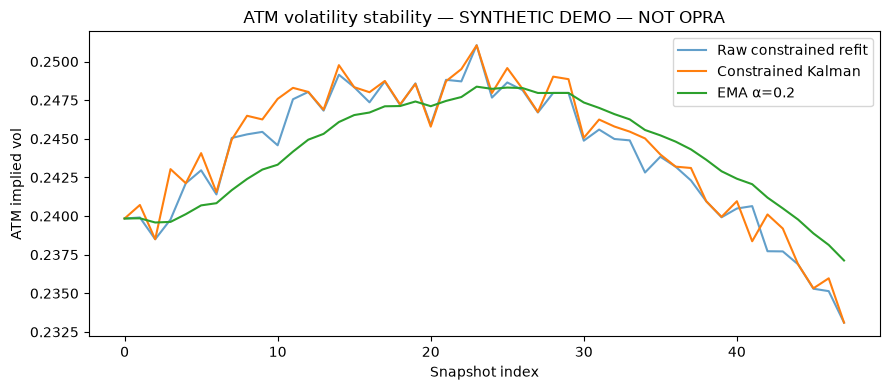

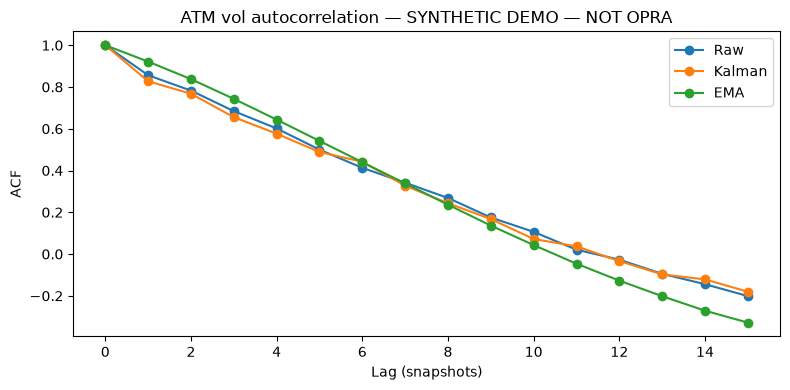

        raw_ATM  kalman_ATM   ema_ATM
count  48.00000    48.00000  48.00000
mean    0.24393     0.24444   0.24416
std     0.00437     0.00439   0.00331
min     0.23310     0.23310   0.23712
25%     0.24060     0.24096   0.24110
50%     0.24494     0.24563   0.24488
75%     0.24774     0.24808   0.24711
max     0.25106     0.25105   0.24838


In [9]:
raw=np.sqrt(fits[:,0]);kal=np.sqrt(filtered[:,0]);ema=pd.Series(raw).ewm(alpha=.2,adjust=False).mean().to_numpy()
fig,ax=plt.subplots(figsize=(9,4));ax.plot(raw,label='Raw constrained refit',alpha=.7);ax.plot(kal,label='Constrained Kalman');ax.plot(ema,label='EMA α=0.2')
ax.set(xlabel='Snapshot index',ylabel='ATM implied vol',title='ATM volatility stability — '+SOURCE);ax.legend();plt.tight_layout();plt.show()
lag=min(15,len(raw)//3)
plt.figure(figsize=(8,4))
for label,series in [('Raw',raw),('Kalman',kal),('EMA',ema)]:plt.plot(np.arange(lag+1),acf(series,nlags=lag,fft=False),marker='o',label=label)
plt.xlabel('Lag (snapshots)');plt.ylabel('ACF');plt.title('ATM vol autocorrelation — '+SOURCE);plt.legend();plt.tight_layout();plt.show()
print(pd.DataFrame({'raw_ATM':raw,'kalman_ATM':kal,'ema_ATM':ema}).describe().round(5))


## 10. Findings, market-making trade-offs, and presentation plan
**Demonstrated on synthetic data:** pricing inversion, chain-rule slope conversion, constrained smile fits, dense-grid static-arbitrage validation, one-step-ahead price diagnostics, and the constrained Kalman / unconstrained-posterior identity test.

**What temporal smoothing buys:** less snapshot-to-snapshot quote jitter, smoother Greeks and inventory hedges, and a principled noise-vs-state-drift tradeoff. **Costs:** filter covariance calibration, extra computation, lag during market regime shifts, approximate linearization of endogenous SNS coordinates, and possible numerical projection failures.

**Important limitations:** (i) real OPRA full-day results are pending data; (ii) this implementation uses Black–Scholes rather than the unavailable Exercise 2 pricer; (iii) convexity and monotonicity are checked on a finite grid, not proved globally; (iv) polynomial wings should not be extrapolated beyond ±3.5 SNS; (v) dividends, borrow and American early exercise need more careful treatment for equity options; (vi) a projected posterior mean with unchanged covariance is an approximation.

**Suggested PPT sequence:** (1) assignment and data, (2) BS inversion validation, (3) SNS slope derivation, (4) constrained model and arbitrage checks, (5) representative smile, (6) one-step-ahead metrics, (7) Kalman formulation and identity test, (8) ATM series and ACF, (9) market-making implications, (10) limitations and next steps. Replace all demo charts with real OPRA outputs before submission.